# GraphSentinel - XGBoost (GPU) AML model, trained on the IBM AML dataset

Trains a **multi-class XGBoost** edge (transaction) classifier on Kaggle's GPU that
1. flags laundering transactions, and
2. names the **laundering pattern** - all 8 IBM patterns: `FAN-OUT, FAN-IN, GATHER-SCATTER, SCATTER-GATHER, CYCLE, RANDOM, BIPARTITE, STACK`.

Labels for the 8 patterns come from the dataset's own `*_Patterns.txt` (ground truth), not from heuristics.

### Which dataset variant? -> `HI-Medium`
| variant | rows | verdict |
|---|---|---|
| `*-Small` | ~5-7M | too few laundering attempts for the rarer patterns (BIPARTITE, STACK, SCATTER-GATHER) |
| **`HI-Medium`** | ~32M, ~35K laundering | **best trade-off**: hundreds of attempts of every pattern, still fits Kaggle's ~29 GB RAM / 16 GB GPU |
| `*-Large` | ~180M | does not fit in Kaggle RAM with this feature set |
| `HI-` vs `LI-` | high vs low illicit ratio | `HI` = more positives per pattern -> better pattern learning |

Change `VARIANT` in the config cell to try another one (`HI-Small` is a quick smoke test, ~10 min).

### How to run on Kaggle
1. New notebook -> **Add Input** -> dataset `ealtman2019/ibm-transactions-for-anti-money-laundering-aml`.
2. **Settings -> Accelerator -> GPU (T4 x2 or P100)**. Internet is not required.
3. **Run All**. Everything you need to download ends up in `/kaggle/working/graphsentinel_xgb_bundle.zip`.

### Pipeline
`Trans.csv` + `Patterns.txt` -> label every transaction (NORMAL or one of 8 patterns) -> vectorised graph features (`xgb_features.py`, shared with the web-app backend) -> **time-based 60/20/20 split** (no leakage from the future) -> negative down-sampling for training only -> GPU XGBoost -> threshold tuned on validation -> evaluation on the untouched test period, **per pattern** -> export `.pt` bundle.

In [1]:
import os, sys, re, io, gc, json, time, shutil, subprocess, warnings
import numpy as np
import pandas as pd
import xgboost as xgb
warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())

def _has_gpu():
    try:
        r = subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True)
        return r.returncode == 0 and "GPU" in r.stdout
    except FileNotFoundError:
        return False

HAS_GPU = _has_gpu()
XGB_MAJOR = int(xgb.__version__.split(".")[0])
print("xgboost", xgb.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
print("GPU available:", HAS_GPU)
if not HAS_GPU:
    print("WARNING: no GPU found -> training falls back to CPU (slow on HI-Medium). Settings -> Accelerator -> GPU.")
if XGB_MAJOR < 2:
    print("WARNING: xgboost < 2.0, using the legacy 'gpu_hist' API.")

xgboost 3.4.1 | pandas 2.3.3 | numpy 2.1.3
GPU available: True


In [2]:
# ----------------------------- CONFIG --------------------------------------
VARIANT      = os.environ.get("GS_VARIANT", "HI-Medium")     # HI|LI - Small|Medium|Large
DATA_DIR     = os.environ.get("GS_DATA_DIR", "")             # empty = search /kaggle/input
OUT_DIR      = os.environ.get("GS_OUT_DIR", "/kaggle/working" if os.path.isdir("/kaggle/working") else ".")
SEED         = 42

TRAIN_FRAC, VAL_FRAC = 0.60, 0.20        # remaining 20% = test (chronological split)
NEG_PER_POS  = int(os.environ.get("GS_NEG_PER_POS", 100))   # normal rows kept per laundering row (TRAIN/VAL only)
MAX_ROUNDS   = int(os.environ.get("GS_MAX_ROUNDS", 600))
EARLY_STOP   = 40
MAX_MODEL_MB = 90                        # GitHub rejects files > 100 MB; keep headroom

XGB_PARAMS = dict(
    objective="multi:softprob", eval_metric="mlogloss",
    max_depth=7, eta=0.10, subsample=0.8, colsample_bytree=0.8,
    min_child_weight=2, reg_lambda=2.0, max_bin=256, seed=SEED,
)
if XGB_MAJOR >= 2:
    XGB_PARAMS.update(tree_method="hist", device="cuda" if HAS_GPU else "cpu")
else:
    XGB_PARAMS.update(tree_method="gpu_hist" if HAS_GPU else "hist")

def find_file(name):
    roots = [DATA_DIR] if DATA_DIR else ["/kaggle/input"]
    for root in roots:
        for dp, _, fs in os.walk(root):
            for f in fs:
                if f.lower() == name.lower():
                    return os.path.join(dp, f)
    raise FileNotFoundError(f"{name} not found under {roots}. Did you add the IBM AML dataset as notebook input?")

TRANS_PATH    = find_file(f"{VARIANT}_Trans.csv")
ACCOUNTS_PATH = find_file(f"{VARIANT}_accounts.csv")
PATTERNS_PATH = find_file(f"{VARIANT}_Patterns.txt")
print("variant  :", VARIANT)
for p in (TRANS_PATH, ACCOUNTS_PATH, PATTERNS_PATH):
    print(f"  {os.path.getsize(p)/1e6:9.1f} MB  {p}")
print("params   :", XGB_PARAMS)

variant  : HI-Medium
     3031.8 MB  /kaggle/input/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/HI-Medium_Trans.csv
      145.0 MB  /kaggle/input/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/HI-Medium_accounts.csv
        2.3 MB  /kaggle/input/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/HI-Medium_Patterns.txt
params   : {'objective': 'multi:softprob', 'eval_metric': 'mlogloss', 'max_depth': 7, 'eta': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_weight': 2, 'reg_lambda': 2.0, 'max_bin': 256, 'seed': 42, 'tree_method': 'hist', 'device': 'cuda'}


## 1. Shared modules
These two files are written next to the notebook and are shipped **unchanged** to your backend (`model/app/`). One feature implementation for training and serving = no train/serve skew.

In [3]:
%%writefile xgb_features.py
"""
xgb_features.py - shared feature engineering for the GraphSentinel XGBoost AML model.

The SAME file is used by the Kaggle training notebook and by the FastAPI
inference service, so training and serving can never drift apart.

Input  : a transactions DataFrame with the IBM AML columns
         Timestamp, From Bank, Account, To Bank, Account.1,
         Amount Received, Receiving Currency, Amount Paid,
         Payment Currency, Payment Format
         (+ optional accounts DataFrame: Bank ID, Account Number, Entity ID)
Output : float32 DataFrame, one row per transaction (original row order),
         columns == FEATURE_COLUMNS.  NaN means "not applicable" and is
         handled natively by XGBoost.

Everything is vectorised numpy (no python loops over rows) so it scales to the
~32M row HI-Medium dataset.
"""

import numpy as np
import pandas as pd

# --------------------------------------------------------------------------
# Fixed vocabularies (IBM AML dataset) -> stable codes between train & serve
# --------------------------------------------------------------------------
PAYMENT_FORMATS = ["Reinvestment", "Cheque", "Credit Card", "ACH", "Cash", "Wire", "Bitcoin"]
CURRENCIES = [
    "US Dollar", "Euro", "Yuan", "Shekel", "Rupee", "UK Pound", "Yen", "Ruble",
    "Canadian Dollar", "Australian Dollar", "Swiss Franc", "Brazil Real",
    "Mexican Peso", "Saudi Riyal", "Bitcoin",
]

REQUIRED_TRANS_COLUMNS = [
    "Timestamp", "From Bank", "Account", "To Bank", "Account.1",
    "Amount Received", "Receiving Currency", "Amount Paid",
    "Payment Currency", "Payment Format",
]

_NODE_STATS = [
    "out_cnt", "in_cnt", "out_uniq", "in_uniq",
    "out_sum_log", "in_sum_log",
    "out_mean_log", "out_std_log", "in_mean_log", "in_std_log",
    "flow_ratio",
]

FEATURE_COLUMNS = (
    # ---- edge level ----
    ["amt_paid_log", "amt_recv_log", "amt_log_diff", "cross_currency",
     "pay_fmt", "pay_cur", "recv_cur", "hour", "dow",
     "same_bank", "self_loop", "pair_cnt", "rev_cnt"]
    # ---- sender / receiver node statistics ----
    + [f"s_{k}" for k in _NODE_STATS]
    + [f"r_{k}" for k in _NODE_STATS]
    # ---- amount relative to the accounts' own behaviour ----
    + ["amt_vs_s_out_mean", "amt_vs_r_in_mean"]
    # ---- entity (accounts.csv) ----
    + ["same_entity", "s_ent_accts", "r_ent_accts"]
    # ---- temporal / pass-through behaviour ----
    + ["s_gap_prev_out", "s_gap_next_out", "r_gap_prev_in",
       "s_prev_in_delay", "s_prev_in_amt_ratio",
       "r_next_out_delay", "r_next_out_amt_ratio",
       # ---- burst behaviour (same day / same hour windows) ----
       "s_day_out_cnt", "s_day_out_uniq", "r_day_in_cnt", "r_day_in_uniq",
       "s_day_in_cnt", "r_day_out_cnt", "s_hr_out_cnt", "r_hr_in_cnt"]
)

_GOLD = np.uint64(0x9E3779B97F4A7C15)


# --------------------------------------------------------------------------
# helpers
# --------------------------------------------------------------------------
class _Feat(dict):
    """dict that stores every feature as float32 the moment it is assigned (halves peak RAM)."""

    def __setitem__(self, key, value):
        super().__setitem__(key, np.asarray(value, dtype=np.float32))


def account_keys(bank, acct) -> np.ndarray:
    """uint64 key per (bank, account-number) without building giant strings."""
    acct_arr = pd.Series(acct).astype(str).to_numpy(dtype=object)
    h = pd.util.hash_array(acct_arr)
    bank_u = np.asarray(pd.to_numeric(pd.Series(bank), errors="coerce").fillna(-1), dtype=np.int64).astype(np.uint64)
    with np.errstate(over="ignore"):
        return h + bank_u * _GOLD


def _cat_codes(series: pd.Series, categories) -> np.ndarray:
    """Map a (possibly categorical) string column onto a fixed vocabulary; -1 = unknown."""
    if not isinstance(series.dtype, pd.CategoricalDtype):
        series = series.astype("category")
    lut = {c: i for i, c in enumerate(categories)}
    cat_lut = np.array([lut.get(c, -1) for c in series.cat.categories], dtype=np.int16)
    codes = series.cat.codes.to_numpy()
    out = np.full(len(codes), -1, dtype=np.int16)
    ok = codes >= 0
    out[ok] = cat_lut[codes[ok]]
    return out.astype(np.float32)


def _lookup(sorted_keys: np.ndarray, vals: np.ndarray, query: np.ndarray) -> np.ndarray:
    """vals[key == query] from a sorted unique key table; 0 when absent."""
    if len(sorted_keys) == 0:
        return np.zeros(len(query), dtype=np.float64)
    idx = np.searchsorted(sorted_keys, query)
    idxc = np.minimum(idx, len(sorted_keys) - 1)
    ok = sorted_keys[idxc] == query
    return np.where(ok, vals[idxc], 0).astype(np.float64)


def _gaps(group: np.ndarray, t: np.ndarray, big: int):
    """Minutes to the previous / next STRICTLY earlier / later event of the same group.

    Strict comparison makes the result independent of the row order (ties at the same
    minute no longer depend on which row happens to come first).
    """
    key = group * big + t
    sk = np.sort(key)
    n = len(sk)
    ip = np.searchsorted(sk, key, side="left") - 1
    ipc = np.clip(ip, 0, n - 1)
    okp = (ip >= 0) & (sk[ipc] // big == group)
    prev = np.where(okp, key - sk[ipc], np.nan)
    inx = np.searchsorted(sk, key, side="right")
    inxc = np.minimum(inx, n - 1)
    okn = (inx < n) & (sk[inxc] // big == group)
    nxt = np.where(okn, sk[inxc] - key, np.nan)
    return prev, nxt


def _count_table(keys: np.ndarray):
    uk, inv, cnt = np.unique(keys, return_inverse=True, return_counts=True)
    return uk, cnt, cnt[inv.ravel()].astype(np.float64)


def _uniq_table(group_keys: np.ndarray, member: np.ndarray, member_range: int):
    """number of distinct `member` values inside every group key -> (sorted keys, counts)."""
    triple = np.unique(group_keys * member_range + member)
    uk, cnt = np.unique(triple // member_range, return_counts=True)
    return uk, cnt


# --------------------------------------------------------------------------
# main entry point
# --------------------------------------------------------------------------
def build_features(df: pd.DataFrame, accounts_df: pd.DataFrame = None, as_numpy: bool = False):
    """Return a float32 DataFrame (default) or, with as_numpy=True, an (n, len(FEATURE_COLUMNS)) ndarray."""
    n = len(df)
    ts = pd.to_datetime(df["Timestamp"])
    t = (((ts - ts.min()).dt.total_seconds()) // 60).to_numpy(dtype=np.int64)   # minutes
    hour = ts.dt.hour.to_numpy()
    dow = ts.dt.dayofweek.to_numpy()

    paid = df["Amount Paid"].astype("float64").fillna(0).to_numpy()
    recv = df["Amount Received"].astype("float64").fillna(0).to_numpy()
    lp = np.log1p(paid)
    lr = np.log1p(recv)

    # ---------------- node ids ----------------
    ks = account_keys(df["From Bank"], df["Account"])
    kr = account_keys(df["To Bank"], df["Account.1"])
    codes, node_keys = pd.factorize(np.concatenate([ks, kr]))
    s = codes[:n].astype(np.int64)
    r = codes[n:].astype(np.int64)
    del codes, ks, kr
    N = len(node_keys)

    # ---------------- node statistics ----------------
    out_cnt = np.bincount(s, minlength=N).astype(np.float64)
    in_cnt = np.bincount(r, minlength=N).astype(np.float64)
    out_sum = np.bincount(s, weights=paid, minlength=N)
    in_sum = np.bincount(r, weights=recv, minlength=N)
    oc = np.maximum(out_cnt, 1)
    ic = np.maximum(in_cnt, 1)
    out_mean = np.bincount(s, weights=lp, minlength=N) / oc
    in_mean = np.bincount(r, weights=lr, minlength=N) / ic
    out_sq = np.bincount(s, weights=lp * lp, minlength=N) / oc
    in_sq = np.bincount(r, weights=lr * lr, minlength=N) / ic
    out_std = np.sqrt(np.maximum(out_sq - out_mean ** 2, 0))
    in_std = np.sqrt(np.maximum(in_sq - in_mean ** 2, 0))

    pair_key = s * N + r
    upk, inv, pc = np.unique(pair_key, return_inverse=True, return_counts=True)
    pair_cnt = pc[inv.ravel()].astype(np.float64)
    out_uniq = np.bincount(upk // N, minlength=N).astype(np.float64)
    in_uniq = np.bincount(upk % N, minlength=N).astype(np.float64)
    rev_cnt = _lookup(upk, pc, r * N + s)
    del pair_key, inv

    node_stats = {
        "out_cnt": out_cnt, "in_cnt": in_cnt, "out_uniq": out_uniq, "in_uniq": in_uniq,
        "out_sum_log": np.log1p(out_sum), "in_sum_log": np.log1p(in_sum),
        "out_mean_log": out_mean, "out_std_log": out_std,
        "in_mean_log": in_mean, "in_std_log": in_std,
        "flow_ratio": np.log1p(in_sum) - np.log1p(out_sum),
    }

    base = {
        "amt_paid_log": lp,
        "amt_recv_log": lr,
        "amt_log_diff": lr - lp,
        "pay_fmt": _cat_codes(df["Payment Format"], PAYMENT_FORMATS),
        "pay_cur": _cat_codes(df["Payment Currency"], CURRENCIES),
        "recv_cur": _cat_codes(df["Receiving Currency"], CURRENCIES),
        "hour": hour,
        "dow": dow,
        "same_bank": (df["From Bank"].to_numpy() == df["To Bank"].to_numpy()).astype(np.float32),
        "self_loop": (s == r).astype(np.float32),
        "pair_cnt": pair_cnt,
        "rev_cnt": rev_cnt,
    }
    feat = _Feat()
    for _k, _v in base.items():
        feat[_k] = _v
    del base
    # cross-currency compared on the fixed vocabulary codes (works for category & object dtypes)
    feat["cross_currency"] = (feat["pay_cur"] != feat["recv_cur"]).astype(np.float32)

    for prefix, idx in (("s", s), ("r", r)):
        for k, arr in node_stats.items():
            feat[f"{prefix}_{k}"] = arr[idx]
    feat["amt_vs_s_out_mean"] = lp - feat["s_out_mean_log"]
    feat["amt_vs_r_in_mean"] = lr - feat["r_in_mean_log"]

    # ---------------- entity features (optional accounts.csv) ----------------
    nan_arr = np.full(n, np.nan)
    feat["same_entity"], feat["s_ent_accts"], feat["r_ent_accts"] = nan_arr, nan_arr.copy(), nan_arr.copy()
    if accounts_df is not None and len(accounts_df):
        try:
            ka = account_keys(accounts_df["Bank ID"], accounts_df["Account Number"])
            ent_codes, _ = pd.factorize(accounts_df["Entity ID"].astype(str))
            ent_n = np.bincount(ent_codes).astype(np.float64)
            order = np.argsort(ka)
            ka_sorted = ka[order]
            pos = np.minimum(np.searchsorted(ka_sorted, node_keys), len(ka_sorted) - 1)
            valid = ka_sorted[pos] == node_keys
            node_ent = np.where(valid, ent_codes[order[pos]], -1)
            node_ent_n = np.where(valid, ent_n[np.maximum(node_ent, 0)], np.nan)
            se, re_ = node_ent[s], node_ent[r]
            feat["same_entity"] = np.where((se >= 0) & (re_ >= 0), (se == re_).astype(np.float64), np.nan)
            feat["s_ent_accts"] = node_ent_n[s]
            feat["r_ent_accts"] = node_ent_n[r]
        except KeyError:
            pass   # accounts file without the expected columns -> leave NaN

    # ---------------- temporal / pass-through ----------------
    BIG = int(t.max()) + 2
    s_prev, s_next = _gaps(s, t, BIG)
    r_prev, _ = _gaps(r, t, BIG)
    feat["s_gap_prev_out"], feat["s_gap_next_out"], feat["r_gap_prev_in"] = s_prev, s_next, r_prev
    # event tables sorted by (node, minute, amount) -> deterministic even with ties
    out_order = np.lexsort((lp, t, s))
    in_order = np.lexsort((lr, t, r))

    out_node, out_t, out_lp = s[out_order], t[out_order], lp[out_order]
    out_keys = out_node * BIG + out_t
    in_node, in_t, in_lr = r[in_order], t[in_order], lr[in_order]
    in_keys = in_node * BIG + in_t

    # when did the SENDER last receive money (strictly before this transfer)?
    idx = np.searchsorted(in_keys, s * BIG + t, side="left") - 1
    idxc = np.clip(idx, 0, n - 1)
    ok = (idx >= 0) & (in_node[idxc] == s)
    feat["s_prev_in_delay"] = np.where(ok, t - in_t[idxc], np.nan)
    feat["s_prev_in_amt_ratio"] = np.where(ok, lp - in_lr[idxc], np.nan)

    # when does the RECEIVER next forward money?
    idx = np.searchsorted(out_keys, r * BIG + t, side="left")
    idxc = np.minimum(idx, n - 1)
    ok = (idx < n) & (out_node[idxc] == r)
    feat["r_next_out_delay"] = np.where(ok, out_t[idxc] - t, np.nan)
    feat["r_next_out_amt_ratio"] = np.where(ok, out_lp[idxc] - lr, np.nan)

    # ---------------- burst windows ----------------
    day = t // 1440
    ND = int(day.max()) + 2
    out_day_key = s * ND + day
    in_day_key = r * ND + day
    uk_o, c_o, feat["s_day_out_cnt"] = _count_table(out_day_key)
    uk_i, c_i, feat["r_day_in_cnt"] = _count_table(in_day_key)
    feat["s_day_in_cnt"] = _lookup(uk_i, c_i, s * ND + day)
    feat["r_day_out_cnt"] = _lookup(uk_o, c_o, r * ND + day)
    uk, cnt = _uniq_table(out_day_key, r, N)
    feat["s_day_out_uniq"] = _lookup(uk, cnt, out_day_key)
    uk, cnt = _uniq_table(in_day_key, s, N)
    feat["r_day_in_uniq"] = _lookup(uk, cnt, in_day_key)

    hr = t // 60
    NH = int(hr.max()) + 2
    _, _, feat["s_hr_out_cnt"] = _count_table(s * NH + hr)
    _, _, feat["r_hr_in_cnt"] = _count_table(r * NH + hr)

    missing = set(FEATURE_COLUMNS) - set(feat)
    extra = set(feat) - set(FEATURE_COLUMNS)
    assert not missing and not extra, f"feature mismatch: missing={missing} extra={extra}"
    if as_numpy:
        X = np.empty((n, len(FEATURE_COLUMNS)), dtype=np.float32)
        for j, c in enumerate(FEATURE_COLUMNS):
            X[:, j] = feat.pop(c)          # free each column as soon as it is copied
        return X
    return pd.DataFrame({c: feat[c] for c in FEATURE_COLUMNS})


Writing xgb_features.py


In [4]:
%%writefile xgb_loader.py
"""
xgb_loader.py - load the GraphSentinel XGBoost AML model from a .pt bundle.

The .pt file is a plain torch dict (loadable with torch.load(..., weights_only=True))
that carries the serialized XGBoost booster as a uint8 tensor, so it can live in the
same /models folder and be handled with the same tooling as the old EdgeGAT .pth files.

    bundle = {
        "format":          "graphsentinel-xgboost-v1",
        "booster_ubj":     uint8 tensor   # xgboost Booster.save_raw("ubj")
        "feature_columns": [str, ...]     # exact column order the booster expects
        "classes":         ["NORMAL", "FAN-OUT", ... ]
        "threshold":       float          # laundering-score threshold tuned on validation
        "variant":         "HI-Medium",
        "metrics":         {...},
    }
"""

import numpy as np
import pandas as pd
import torch
import xgboost as xgb

BUNDLE_FORMAT = "graphsentinel-xgboost-v1"

# names used by the rest of the GraphSentinel backend / explainer prompt
DISPLAY_NAMES = {
    "FAN-OUT": "Fan-out",
    "FAN-IN": "Fan-in",
    "GATHER-SCATTER": "Gather-scatter",
    "SCATTER-GATHER": "Scatter-gather",
    "CYCLE": "Simple Cycle",
    "RANDOM": "Random",
    "BIPARTITE": "Bipartite",
    "STACK": "Stack",
    "OTHER-LAUNDERING": "Random",
}


def is_xgb_bundle(path: str) -> bool:
    """True if `path` is an XGBoost bundle (False for legacy EdgeGAT state_dict files)."""
    try:
        obj = torch.load(path, map_location="cpu", weights_only=True)
    except Exception:
        return False
    return isinstance(obj, dict) and obj.get("format") == BUNDLE_FORMAT


class XGBAMLModel:
    def __init__(self, bundle: dict, device: str = "cpu"):
        if bundle.get("format") != BUNDLE_FORMAT:
            raise ValueError("Not a GraphSentinel XGBoost bundle")
        raw = bundle["booster_ubj"].cpu().numpy().astype(np.uint8).tobytes()
        self.booster = xgb.Booster()
        self.booster.load_model(bytearray(raw))
        self.booster.set_param({"device": device})
        self.feature_columns = list(bundle["feature_columns"])
        self.classes = list(bundle["classes"])
        self.threshold = float(bundle.get("threshold", 0.5))
        self.variant = bundle.get("variant", "")
        self.metrics = bundle.get("metrics", {})
        self.size_bytes = int(len(raw))

    # -- inference ---------------------------------------------------------
    def predict_proba(self, X: pd.DataFrame, batch: int = 1_000_000) -> np.ndarray:
        """(n_rows, n_classes) class probabilities; column 0 is NORMAL."""
        arr = X[self.feature_columns].to_numpy(dtype=np.float32)
        out = np.empty((len(arr), len(self.classes)), dtype=np.float32)
        for i in range(0, len(arr), batch):
            dm = xgb.DMatrix(arr[i:i + batch], feature_names=self.feature_columns)
            out[i:i + batch] = self.booster.predict(dm)
        return out

    def score(self, proba: np.ndarray) -> np.ndarray:
        """P(laundering) = 1 - P(NORMAL)."""
        return 1.0 - proba[:, 0]

    def pattern_index(self, proba: np.ndarray) -> np.ndarray:
        """Most likely laundering pattern (index >= 1) per row."""
        return proba[:, 1:].argmax(axis=1) + 1

    def pattern_name(self, idx: int, pretty: bool = True) -> str:
        name = self.classes[int(idx)]
        return DISPLAY_NAMES.get(name, name) if pretty else name


def load_xgb_model(path: str, device: str = "cpu") -> XGBAMLModel:
    bundle = torch.load(path, map_location="cpu", weights_only=True)
    return XGBAMLModel(bundle, device=device)


Writing xgb_loader.py


## 2. Load transactions

In [5]:
COLS = ["Timestamp", "From Bank", "Account", "To Bank", "Account.1", "Amount Received",
        "Receiving Currency", "Amount Paid", "Payment Currency", "Payment Format", "Is Laundering"]
_dt = {"Account": "str", "Account.1": "str", "Amount Received": "float64", "Amount Paid": "float64",
       "Receiving Currency": "category", "Payment Currency": "category",
       "Payment Format": "category", "Is Laundering": "int8"}

t0 = time.time()
try:
    df = pd.read_csv(TRANS_PATH, header=0, names=COLS, dtype={**_dt, "From Bank": "int32", "To Bank": "int32"})
except (ValueError, OverflowError):
    df = pd.read_csv(TRANS_PATH, header=0, names=COLS, dtype={**_dt, "From Bank": "str", "To Bank": "str"})
    for c in ("From Bank", "To Bank"):
        df[c] = pd.to_numeric(df[c], errors="coerce").fillna(-1).astype("int32")
df["Timestamp"] = pd.to_datetime(df["Timestamp"], format="%Y/%m/%d %H:%M", errors="coerce")
df = df.dropna(subset=["Timestamp"]).reset_index(drop=True)

n_all, n_laund = len(df), int(df["Is Laundering"].sum())
print(f"loaded {n_all:,} transactions in {time.time()-t0:.0f}s | laundering: {n_laund:,} ({100*n_laund/n_all:.3f}%)")
print("period:", df["Timestamp"].min(), "->", df["Timestamp"].max())
print(f"RAM used by dataframe: {df.memory_usage(deep=True).sum()/1e9:.1f} GB")
df.head(3)

loaded 31,898,238 transactions in 72s | laundering: 35,230 (0.110%)
period: 2022-09-01 00:00:00 -> 2022-09-28 15:58:00
RAM used by dataframe: 4.8 GB


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022-09-01 00:17:00,20,800104D70,20,800104D70,6794.63,US Dollar,6794.63,US Dollar,Reinvestment,0
1,2022-09-01 00:02:00,3196,800107150,3196,800107150,7739.29,US Dollar,7739.29,US Dollar,Reinvestment,0
2,2022-09-01 00:17:00,1208,80010E430,1208,80010E430,1880.23,US Dollar,1880.23,US Dollar,Reinvestment,0


## 3. Pattern labels from `Patterns.txt`
Each `BEGIN LAUNDERING ATTEMPT - <PATTERN>` block lists the transactions of one laundering attempt. We match those rows back to the transaction table, so **every laundering transaction gets its true pattern class** (and an attempt id, used later for attempt-level recall).

In [6]:
CANON = ["FAN-OUT", "FAN-IN", "GATHER-SCATTER", "SCATTER-GATHER", "CYCLE", "RANDOM", "BIPARTITE", "STACK"]
BEGIN_RE = re.compile(r"BEGIN LAUNDERING ATTEMPT\s*-\s*([A-Za-z\-]+)", re.I)

def parse_patterns(path):
    lines, types, attempts, cur, aid = [], [], [], None, -1
    with open(path, encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            m = BEGIN_RE.match(line)
            if m:
                cur = m.group(1).upper().rstrip("-"); aid += 1
                continue
            if line.upper().startswith("END LAUNDERING ATTEMPT"):
                cur = None
                continue
            if cur is not None:
                lines.append(line); types.append(cur); attempts.append(aid)
    p = pd.read_csv(io.StringIO("\n".join(lines)), header=None, names=COLS,
                    dtype={"Account": "str", "Account.1": "str", "From Bank": "str", "To Bank": "str"})
    p["Timestamp"] = pd.to_datetime(p["Timestamp"], format="%Y/%m/%d %H:%M")
    for c in ("From Bank", "To Bank"):
        p[c] = pd.to_numeric(p[c]).astype("int64")
    p["ptype"], p["attempt"] = types, attempts
    return p

def row_key(d):
    return (d["Timestamp"].dt.strftime("%Y%m%d%H%M") + "|" + d["From Bank"].astype("int64").astype(str) + "|"
            + d["Account"].astype(str) + "|" + d["To Bank"].astype("int64").astype(str) + "|"
            + d["Account.1"].astype(str) + "|" + d["Amount Paid"].astype("float64").round(4).astype(str)
            + "|" + d["Payment Format"].astype(str))

pat = parse_patterns(PATTERNS_PATH)
pat["key"] = row_key(pat)
n_attempts = pat["attempt"].nunique()
pat = pat.drop_duplicates("key")
print(f"Patterns.txt: {n_attempts:,} laundering attempts, {len(pat):,} unique transactions")

lab_idx = np.flatnonzero(df["Is Laundering"].to_numpy() == 1)
keys = row_key(df.iloc[lab_idx])
m_type = keys.map(dict(zip(pat["key"], pat["ptype"])))
m_att = keys.map(dict(zip(pat["key"], pat["attempt"])))

found = sorted(set(pat["ptype"]))
CLASSES = ["NORMAL"] + [c for c in CANON if c in found] + [c for c in found if c not in CANON]
n_unmatched = int(m_type.isna().sum())
if n_unmatched > 0:
    CLASSES.append("OTHER-LAUNDERING")
CLS_ID = {c: i for i, c in enumerate(CLASSES)}
K = len(CLASSES)

y = np.zeros(len(df), dtype=np.int8)
y[lab_idx] = m_type.map(CLS_ID).fillna(CLS_ID.get("OTHER-LAUNDERING", 0)).astype(int).to_numpy()
attempt = np.full(len(df), -1, dtype=np.int32)
attempt[lab_idx] = m_att.fillna(-1).astype(int).to_numpy()

missing = [c for c in CANON if c not in found]
print(f"laundering rows matched to a pattern: {len(lab_idx)-n_unmatched:,} / {len(lab_idx):,}  (unmatched -> OTHER-LAUNDERING: {n_unmatched:,})")
if missing:
    print("WARNING - patterns absent from this file:", missing)
print()
print(pd.Series(np.bincount(y, minlength=K), index=CLASSES, name="transactions").to_frame()
        .assign(attempts=[0] + [pat[pat.ptype == c]["attempt"].nunique() for c in CLASSES[1:K - (n_unmatched > 0)]] + ([0] if n_unmatched > 0 else [])))

Patterns.txt: 2,756 laundering attempts, 22,743 unique transactions
laundering rows matched to a pattern: 22,743 / 35,230  (unmatched -> OTHER-LAUNDERING: 12,487)

                  transactions  attempts
NORMAL                31863008         0
FAN-OUT                   2128       345
FAN-IN                    2315       355
GATHER-SCATTER            4289       322
SCATTER-GATHER            3988       331
CYCLE                     2235       367
RANDOM                    1667       331
BIPARTITE                 2135       369
STACK                     3986       336
OTHER-LAUNDERING         12487         0


## 4. Features
~55 vectorised features per transaction: amount / currency / format, sender & receiver degree and flow statistics, pair & reverse-pair counts, pass-through timing (how soon the receiver forwards the money, how long since the sender received it), same-day / same-hour burst counts and entity ownership from `accounts.csv`. They are what lets a tabular model "see" fan-out, fan-in, cycles, layers and bipartite blocks.

In [7]:
import importlib, xgb_features
importlib.reload(xgb_features)
from xgb_features import build_features, FEATURE_COLUMNS

accounts_df = pd.read_csv(ACCOUNTS_PATH, dtype={"Account Number": "str"})
t0 = time.time()
X = build_features(df, accounts_df, as_numpy=True)          # (n, n_features) float32
print(f"features: {X.shape}  ({X.nbytes/1e9:.1f} GB)  built in {time.time()-t0:.0f}s")

t_key = df["Timestamp"].to_numpy().astype("datetime64[s]").astype(np.int64)
del df, accounts_df; gc.collect()
print("NaN share per feature (top 6):")
print(pd.Series(np.isnan(X[:: max(1, len(X)//500_000)]).mean(0), index=FEATURE_COLUMNS).sort_values(ascending=False).head(6).round(3).to_dict())

features: (31898238, 55)  (7.0 GB)  built in 281s
NaN share per feature (top 6):
{'r_next_out_amt_ratio': 0.425, 'r_next_out_delay': 0.425, 's_prev_in_amt_ratio': 0.098, 's_prev_in_delay': 0.098, 's_gap_next_out': 0.064, 's_gap_prev_out': 0.064}


## 5. Chronological split + training sample
60 % oldest -> train, next 20 % -> validation (early stopping + threshold), newest 20 % -> **test** (never touched until the end). Normal transactions are down-sampled **only for training/early-stopping**; validation threshold and all reported metrics use the *full, real* class distribution.

In [8]:
order = np.argsort(t_key, kind="stable")
n = len(order); n1, n2 = int(n * TRAIN_FRAC), int(n * (TRAIN_FRAC + VAL_FRAC))
tr_idx, va_idx, te_idx = order[:n1], order[n1:n2], order[n2:]
rng = np.random.default_rng(SEED)

def downsample(idx, neg_per_pos):
    pos, neg = idx[y[idx] > 0], idx[y[idx] == 0]
    assert len(pos) > 0, "no laundering rows in this split - use a bigger variant"
    neg = rng.choice(neg, min(len(neg), len(pos) * neg_per_pos), replace=False)
    sel = np.concatenate([pos, neg]); rng.shuffle(sel)
    return sel

tr_sel, va_sel = downsample(tr_idx, NEG_PER_POS), downsample(va_idx, NEG_PER_POS)

# mild class weights so the rare patterns are not drowned by the common ones
cnt = np.bincount(y[tr_sel], minlength=K).astype(float)
ref = cnt[1:][cnt[1:] > 0].max()
w_cls = np.ones(K)
for c in range(1, K):
    w_cls[c] = min(8.0, (ref / max(cnt[c], 1)) ** 0.5)
w_tr = w_cls[y[tr_sel]]

summary = pd.DataFrame({
    "train(sampled)": np.bincount(y[tr_sel], minlength=K),
    "val(sampled)":   np.bincount(y[va_sel], minlength=K),
    "val(full)":      np.bincount(y[va_idx], minlength=K),
    "test(full)":     np.bincount(y[te_idx], minlength=K),
    "class weight":   w_cls.round(2)}, index=CLASSES)
print(f"train {len(tr_idx):,} | val {len(va_idx):,} | test {len(te_idx):,}   (sampled train rows: {len(tr_sel):,})")
summary

train 19,138,942 | val 6,379,648 | test 6,379,648   (sampled train rows: 1,569,136)


,train(sampled),val(sampled),val(full),test(full),class weight
NORMAL,1553600,905200,6370596,6369006,1.00
FAN-OUT,935,569,569,624,2.71
FAN-IN,863,603,603,849,2.82
GATHER-SCATTER,1015,1092,1092,2182,2.60
SCATTER-GATHER,1582,1111,1111,1295,2.08
CYCLE,948,564,564,723,2.69
RANDOM,674,452,452,541,3.19
BIPARTITE,1028,606,606,501,2.58
STACK,1633,924,924,1429,2.05
OTHER-LAUNDERING,6858,3131,3131,2498,1.00


## 6. Train XGBoost on the GPU

In [9]:
params = {**XGB_PARAMS, "num_class": K}
dtr = xgb.QuantileDMatrix(X[tr_sel], label=y[tr_sel], weight=w_tr, feature_names=FEATURE_COLUMNS, max_bin=params["max_bin"])
dva = xgb.QuantileDMatrix(X[va_sel], label=y[va_sel], feature_names=FEATURE_COLUMNS, ref=dtr)

t0 = time.time()
booster = xgb.train(params, dtr, num_boost_round=MAX_ROUNDS, evals=[(dtr, "train"), (dva, "val")],
                    early_stopping_rounds=EARLY_STOP, verbose_eval=25)
best_round = booster.best_iteration + 1
print(f"\ntrained in {time.time()-t0:.0f}s on device={params.get('device', params['tree_method'])} | best round: {best_round}")
booster = booster[:best_round]                       # keep only the useful trees (smaller file)
if XGB_MAJOR >= 2:
    booster.set_param({"device": params["device"]})
del dtr, dva; gc.collect()

[0]	train-mlogloss:0.07804	val-mlogloss:0.05857
[25]	train-mlogloss:0.03129	val-mlogloss:0.02732
[50]	train-mlogloss:0.02323	val-mlogloss:0.02417
[75]	train-mlogloss:0.01918	val-mlogloss:0.02327
[100]	train-mlogloss:0.01642	val-mlogloss:0.02288
[125]	train-mlogloss:0.01446	val-mlogloss:0.02273
[150]	train-mlogloss:0.01294	val-mlogloss:0.02265
[175]	train-mlogloss:0.01173	val-mlogloss:0.02263
[200]	train-mlogloss:0.01080	val-mlogloss:0.02263
[213]	train-mlogloss:0.01035	val-mlogloss:0.02264

trained in 48s on device=cuda | best round: 174


35

## 7. Evaluation
* **Threshold** = laundering score `1 - P(NORMAL)` that maximises F1 on the *validation* period.
* Everything below is on the *test* period (the newest 20 % of transactions) with the real, imbalanced class ratio.

In [10]:
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score)

def predict_rows(booster, idx, batch=1_000_000):
    out = np.empty((len(idx), K), dtype=np.float32)
    for i in range(0, len(idx), batch):
        sl = idx[i:i + batch]
        out[i:i + len(sl)] = booster.predict(xgb.DMatrix(X[sl], feature_names=FEATURE_COLUMNS))
    return out

# ---- threshold from validation ----
P_va = predict_rows(booster, va_idx)
sc_va, yb_va = 1 - P_va[:, 0], (y[va_idx] > 0)
prec, rec, thr = precision_recall_curve(yb_va, sc_va)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
THRESHOLD = float(thr[int(np.nanargmax(f1))])
print(f"validation: best-F1 threshold = {THRESHOLD:.3f}  (F1 {f1.max():.3f})")

# ---- test ----
P_te = predict_rows(booster, te_idx)
sc_te, y_te = 1 - P_te[:, 0], y[te_idx]
yb_te = y_te > 0
det = sc_te >= THRESHOLD
pred_pat = P_te[:, 1:].argmax(1) + 1

metrics = {
    "test_pr_auc":        float(average_precision_score(yb_te, sc_te)),
    "test_roc_auc":       float(roc_auc_score(yb_te, sc_te)),
    "test_precision":     float(precision_score(yb_te, det, zero_division=0)),
    "test_recall":        float(recall_score(yb_te, det, zero_division=0)),
    "test_f1":            float(f1_score(yb_te, det, zero_division=0)),
    "test_flagged":       int(det.sum()),
    "test_laundering_tx": int(yb_te.sum()),
    "threshold":          THRESHOLD,
    "best_round":         int(best_round),
    "val_f1":             float(f1.max()),
}
pat_mask = yb_te & det
metrics["pattern_id_accuracy_on_detected"] = float((pred_pat[pat_mask] == y_te[pat_mask]).mean()) if pat_mask.any() else float("nan")
print("\nTEST (laundering vs normal)")
for k in ("test_pr_auc", "test_roc_auc", "test_precision", "test_recall", "test_f1", "pattern_id_accuracy_on_detected"):
    print(f"  {k:34s} {metrics[k]:.4f}")
print(f"  flagged {metrics['test_flagged']:,} of {len(te_idx):,} transactions "
      f"({metrics['test_laundering_tx']:,} are truly laundering)")

validation: best-F1 threshold = 0.883  (F1 0.707)

TEST (laundering vs normal)
  test_pr_auc                        0.8037
  test_roc_auc                       0.9940
  test_precision                     0.9299
  test_recall                        0.6835
  test_f1                            0.7879
  pattern_id_accuracy_on_detected    0.5704
  flagged 7,822 of 6,379,648 transactions (10,642 are truly laundering)


In [11]:
# ---------------- per-pattern report (the 8 patterns) ----------------
rows = []
for c in range(1, K):
    m = y_te == c
    pm = det & (pred_pat == c)
    rows.append({
        "pattern": CLASSES[c],
        "test_tx": int(m.sum()),
        "detected_recall": float(det[m].mean()) if m.any() else np.nan,                         # flagged as laundering at all
        "pattern_id_acc":  float((pred_pat[m & det] == c).mean()) if (m & det).any() else np.nan,  # right pattern name | flagged
        "pattern_precision": float((y_te[pm] == c).mean()) if pm.any() else np.nan,              # when we say "c", how often is it c
    })
per_pattern = pd.DataFrame(rows).set_index("pattern")
metrics["per_pattern"] = {k: {kk: (None if pd.isna(vv) else float(vv)) for kk, vv in v.items()} for k, v in per_pattern.to_dict("index").items()}
print("Per-pattern results on the TEST period")
display(per_pattern.round(3))

# confusion: true pattern (rows) vs predicted pattern (cols); MISSED = scored below threshold
cm = pd.DataFrame(0, index=CLASSES[1:], columns=CLASSES[1:] + ["MISSED"])
for c in range(1, K):
    m = y_te == c
    for pc, cnt_ in zip(*np.unique(np.where(det[m], pred_pat[m], -1), return_counts=True)):
        cm.iloc[c - 1, K - 1 if pc == -1 else pc - 1] = cnt_
print("\nConfusion (rows = true pattern, columns = predicted)")
display(cm)

Per-pattern results on the TEST period


,test_tx,detected_recall,pattern_id_acc,pattern_precision
pattern,,,,
FAN-OUT,624,0.938,0.679,0.496
FAN-IN,849,0.879,0.579,0.561
GATHER-SCATTER,2182,0.949,0.675,0.818
SCATTER-GATHER,1295,0.913,0.560,0.536
CYCLE,723,0.898,0.333,0.350
RANDOM,541,0.895,0.217,0.290
BIPARTITE,501,0.760,0.598,0.307
STACK,1429,0.818,0.605,0.498
OTHER-LAUNDERING,2498,0.003,0.500,0.024



Confusion (rows = true pattern, columns = predicted)


,FAN-OUT,FAN-IN,GATHER-SCATTER,SCATTER-GATHER,CYCLE,RANDOM,BIPARTITE,STACK,OTHER-LAUNDERING,MISSED
FAN-OUT,397,10,20,60,9,4,57,28,0,39
FAN-IN,10,432,68,147,11,2,47,24,5,103
GATHER-SCATTER,248,82,1398,111,30,8,64,129,0,112
SCATTER-GATHER,98,176,107,662,11,10,28,82,8,113
CYCLE,15,18,31,36,216,131,28,172,2,74
RANDOM,5,9,19,19,177,105,22,125,3,57
BIPARTITE,12,8,19,20,16,7,228,70,1,120
STACK,15,15,15,48,83,44,235,707,7,260
OTHER-LAUNDERING,0,0,0,0,0,0,1,3,4,2490


In [12]:
# ---------------- attempt-level recall: did we catch the *ring*? ----------------
att_te = attempt[te_idx]
mk = att_te >= 0
if mk.any():
    a = pd.DataFrame({"att": att_te[mk], "det": det[mk], "cls": y_te[mk]})
    g = a.groupby("att").agg(tx=("det", "size"), coverage=("det", "mean"), cls=("cls", "first"))
    g["pattern"] = [CLASSES[i] for i in g["cls"]]
    att_report = g.groupby("pattern").agg(attempts=("tx", "size"),
                                          any_tx_caught=("coverage", lambda s: float((s > 0).mean())),
                                          majority_caught=("coverage", lambda s: float((s >= 0.5).mean())),
                                          avg_coverage=("coverage", "mean"))
    metrics["attempt_any_caught"] = float((g["coverage"] > 0).mean())
    metrics["attempt_majority_caught"] = float((g["coverage"] >= 0.5).mean())
    print(f"Laundering attempts fully inside the test period: {len(g):,}")
    print(f"  at least one transaction flagged : {metrics['attempt_any_caught']:.1%}")
    print(f"  at least half of the transactions: {metrics['attempt_majority_caught']:.1%}")
    display(att_report.round(3))

Laundering attempts fully inside the test period: 1,227
  at least one transaction flagged : 96.2%
  at least half of the transactions: 94.8%


,attempts,any_tx_caught,majority_caught,avg_coverage
pattern,,,,
BIPARTITE,118,0.941,0.924,0.798
CYCLE,170,0.941,0.941,0.872
FAN-IN,148,0.980,0.959,0.865
FAN-OUT,128,0.969,0.945,0.910
GATHER-SCATTER,212,0.976,0.972,0.908
RANDOM,129,0.938,0.907,0.859
SCATTER-GATHER,159,0.981,0.962,0.892
STACK,163,0.957,0.951,0.807


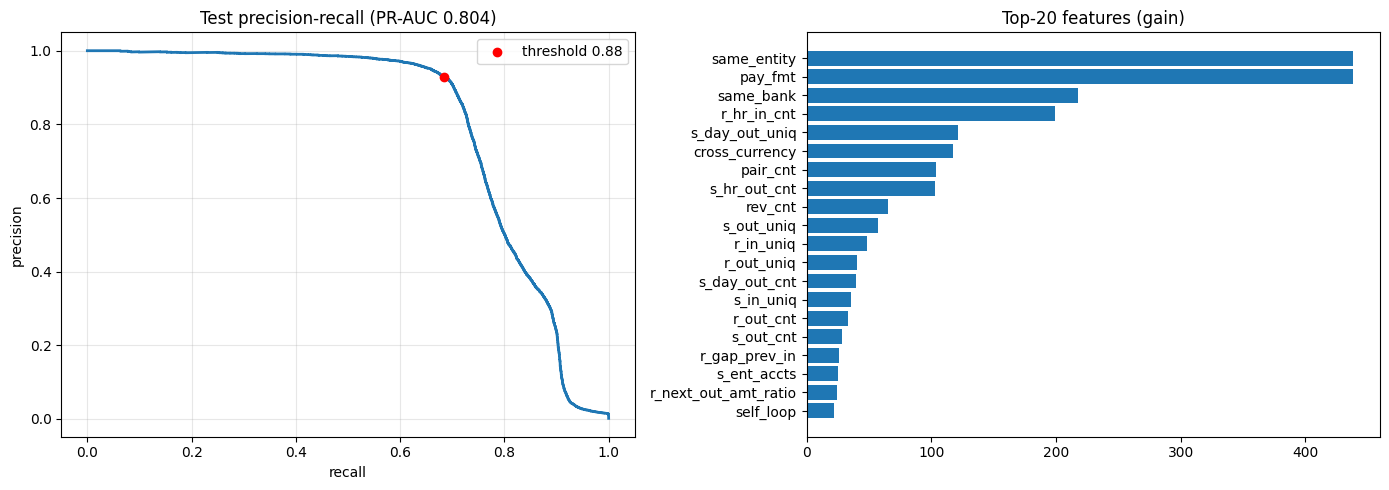

In [13]:
import matplotlib
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
p_t, r_t, _ = precision_recall_curve(yb_te, sc_te)
ax[0].plot(r_t, p_t, lw=2); ax[0].scatter([metrics["test_recall"]], [metrics["test_precision"]], c="red", zorder=3, label=f"threshold {THRESHOLD:.2f}")
ax[0].set(title=f"Test precision-recall (PR-AUC {metrics['test_pr_auc']:.3f})", xlabel="recall", ylabel="precision"); ax[0].legend(); ax[0].grid(alpha=.3)
imp = pd.Series(booster.get_score(importance_type="gain")).sort_values().tail(20)
ax[1].barh(imp.index, imp.values); ax[1].set_title("Top-20 features (gain)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "evaluation.png"), dpi=130); plt.show()

## 8. Export the `.pt` bundle
The `.pt` file is a plain torch dictionary that stores the XGBoost booster as a `uint8` tensor, plus the exact feature order, class names and tuned threshold. It loads with `torch.load(..., weights_only=True)` - the same safe call your backend already uses - and runs on **CPU** in production.

In [14]:
import torch, xgb_loader

BUNDLE_DIR = os.path.join(OUT_DIR, "graphsentinel_xgb_bundle")
os.makedirs(BUNDLE_DIR, exist_ok=True)
pt_name = f"model_xgb_{VARIANT}.pt"
pt_path = os.path.join(BUNDLE_DIR, pt_name)

if XGB_MAJOR >= 2:
    booster.set_param({"device": "cpu"})          # saved model must not carry a CUDA flag (server is CPU-only)
raw = bytes(booster.save_raw(raw_format="ubj"))
flat_metrics = {k: v for k, v in metrics.items() if isinstance(v, (int, float))}
bundle = {
    "format": xgb_loader.BUNDLE_FORMAT,
    "booster_ubj": torch.from_numpy(np.frombuffer(raw, dtype=np.uint8).copy()),
    "feature_columns": list(FEATURE_COLUMNS),
    "classes": list(CLASSES),
    "threshold": float(THRESHOLD),
    "variant": VARIANT,
    "xgboost_version": xgb.__version__,
    "metrics": flat_metrics,
}
torch.save(bundle, pt_path)
size_mb = os.path.getsize(pt_path) / 1e6
print(f"saved {pt_path}  ({size_mb:.1f} MB)")
if size_mb > MAX_MODEL_MB:
    print(f"WARNING: bigger than {MAX_MODEL_MB} MB - too big for a plain GitHub commit. Lower max_depth / MAX_ROUNDS and retrain, "
          "or host the file externally (Google Drive + scripts/download_model.py).")

# ---- round-trip check exactly like the backend will load it (CPU, weights_only=True) ----
chk = xgb_loader.load_xgb_model(pt_path, device="cpu")
samp = np.random.default_rng(0).choice(te_idx, size=min(5000, len(te_idx)), replace=False)
p_new = chk.predict_proba(pd.DataFrame(X[samp], columns=FEATURE_COLUMNS))
p_old = booster.predict(xgb.DMatrix(X[samp], feature_names=FEATURE_COLUMNS))
diff = float(np.abs(p_new - p_old).max())
print(f"round-trip max |dP| = {diff:.2e}  ->", "OK" if diff < 1e-3 else "MISMATCH - do not deploy")
assert diff < 1e-3

for fname in ("xgb_features.py", "xgb_loader.py"):
    shutil.copy(fname, os.path.join(BUNDLE_DIR, fname))
with open(os.path.join(BUNDLE_DIR, "metrics.json"), "w") as f:
    json.dump({"variant": VARIANT, "classes": CLASSES, "threshold": THRESHOLD, **metrics}, f, indent=2)
pd.Series(booster.get_score(importance_type="gain"), name="gain").sort_values(ascending=False).to_csv(os.path.join(BUNDLE_DIR, "feature_importance.csv"))
if os.path.exists(os.path.join(OUT_DIR, "evaluation.png")):
    shutil.copy(os.path.join(OUT_DIR, "evaluation.png"), BUNDLE_DIR)

zip_path = shutil.make_archive(os.path.join(OUT_DIR, "graphsentinel_xgb_bundle"), "zip", BUNDLE_DIR)
print("\nbundle contents:")
for f in sorted(os.listdir(BUNDLE_DIR)):
    print(f"  {os.path.getsize(os.path.join(BUNDLE_DIR, f))/1e6:8.2f} MB  {f}")
print("\ndownload ->", zip_path)

saved /kaggle/working/graphsentinel_xgb_bundle/model_xgb_HI-Medium.pt  (7.7 MB)
round-trip max |dP| = 0.00e+00  -> OK

bundle contents:
      0.08 MB  evaluation.png
      0.00 MB  feature_importance.csv
      0.00 MB  metrics.json
      7.72 MB  model_xgb_HI-Medium.pt
      0.01 MB  xgb_features.py
      0.00 MB  xgb_loader.py

download -> /kaggle/working/graphsentinel_xgb_bundle.zip
